# Experiment 1
## Capturing temporal and non-linear dependencies
### Synthetic data

In [4]:
import sys, os
sys.path.append(os.path.abspath(".."))


from src.imports import *
from src.simulation import consumption_simulate
from src.ridge_signatures import ridge_signatures
from src.baselines import run_baselines_synthetic
from src.utils import setup_latex_plotting

### Load data

In [5]:
base_dir = Path.cwd().parent
file_path = base_dir / "data" / "data.csv"

df = pd.read_csv(file_path, decimal=".")
print(df.head())

df["DateTime"] = pd.to_datetime(df["DateTime"])
temp = np.array(df["Temperature"])
consumption = np.array(df["Consumption"])

              DateTime  HalfHour  Consumption  Temperature
0  2012-01-01 00:00:00         0      58315.0       11.313
1  2012-01-01 00:30:00         1      58315.0       11.273
2  2012-01-01 01:00:00         2      56231.0       11.232
3  2012-01-01 01:30:00         3      56075.0       11.192
4  2012-01-01 02:00:00         4      55532.0       11.152


### Simulate consumption

findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: 

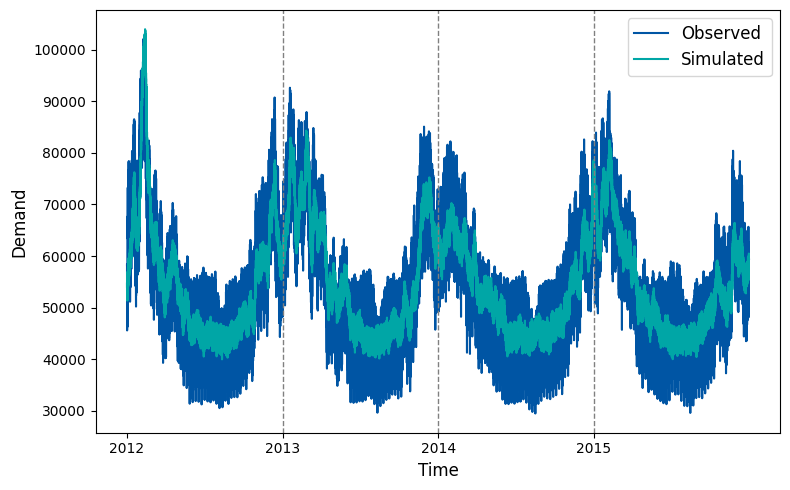

findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: 

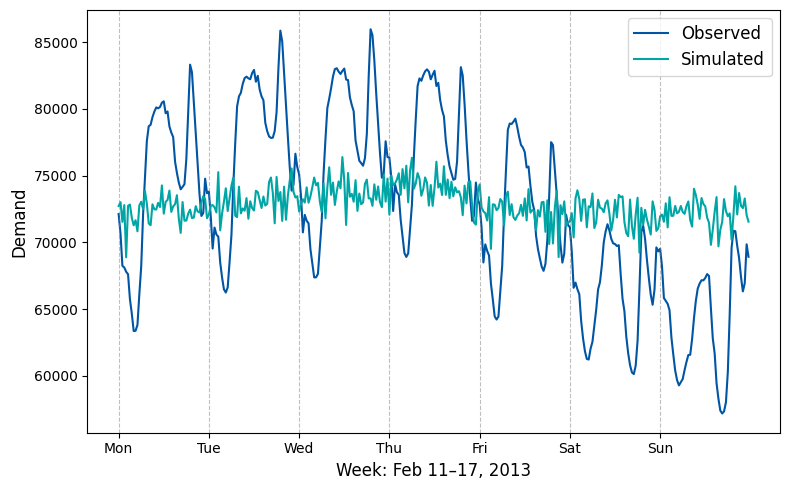

In [6]:
# Parameters
sd_sim = 1000
smooth_param = 0.005
fixed_seed = 141

# Simulate consumption
consumption_sim = consumption_simulate(df, sd_sim, smooth_param, fixed_seed)

setup_latex_plotting()

# Plot simulated versus observed consumption - whole data set (4 years)
observed_color = '#0055A4'   
synthetic_color = '#00A6A6'  
vline_color = 'gray' 

plt.figure(figsize=(8, 5))

plt.plot(consumption, label="Observed", color=observed_color)
plt.plot(consumption_sim, label="Simulated", color=synthetic_color)

plt.ylabel("Demand")
plt.xlabel("Time")

ticks = [0, 366*48, (366+365)*48, (366+365+365)*48]
labels = ['2012', '2013', '2014', '2015']
plt.xticks(ticks, labels)

for x in ticks[1:]:
    plt.axvline(x=x, color=vline_color, linestyle='--', linewidth=1)

plt.legend(fontsize=12)
plt.tight_layout()
plt.show()


# Plot simulated versus observed consumption - one week interval

start = pd.to_datetime("2013-02-11 00:00:00")
end   = pd.to_datetime("2013-02-17 23:30:00")
dates = df["DateTime"]
mask = (dates >= start) & (dates <= end)
consumption_slice = consumption[mask]
consumption_sim_slice = consumption_sim[mask]
dates_slice = dates[mask]

plt.figure(figsize=(8, 5))
plt.plot(consumption_slice, label="Observed", color=observed_color)
plt.plot(consumption_sim_slice, label="Simulated", color=synthetic_color)

for i in range(0, len(consumption_slice), 48):
    plt.axvline(x=i, color=vline_color, linestyle='--', linewidth=0.8, alpha=0.5)

num_days = len(consumption_slice) // 48
day_labels = [(start + pd.Timedelta(days=i)).strftime('%a') for i in range(num_days)]
plt.xticks(ticks=np.arange(0, num_days*48, 48), labels=day_labels)

plt.ylabel("Demand")
plt.xlabel("Week: Feb 11–17, 2013")
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()


### Fitting ridge regression on sliding-window signatures

In [7]:
# Parameters for ridge regression on sliding-window signatures
delay_days = 2  
delay = delay_days*48
n_windows = 31
windows_days = np.array(range(delay_days, n_windows + delay_days))
windows = [48 * i for i in windows_days]
lambdas = np.logspace(-3, 3, 50)
n_train = (df["DateTime"] < "2014-01-01 00:00:00").sum()
n_valid = ((df["DateTime"] >= "2014-01-01 00:00:00") & 
           (df["DateTime"] <  "2015-01-01 00:00:00")).sum()



# Fitting the model; obtaining error metrics

metrics = ["rmse", "mape"]  
errors = {m: np.zeros(len(windows)) for m in metrics}
trunc_order = 4

for metric in metrics:
    for i, w in enumerate(windows):
        result = ridge_signatures(
            covariates=temp,
            target=consumption_sim,
            window=w,
            delay=48 * delay_days,
            n_train=n_train,
            n_valid=n_valid,
            trunc_order=trunc_order,
            penalties=lambdas,
            tune_penalty=True,
            metric=metric,
            max_window = max(windows) 
        )
        errors[metric][i] = result["error_test"]

Signature shape: (70128, 26)
X_train: (33552, 26)
X_val: (17520, 26)
X_test: (17520, 26)
-----------------------------------------
total train+val+test: 68592
total data: 68592
Signature shape: (70128, 26)
X_train: (33552, 26)
X_val: (17520, 26)
X_test: (17520, 26)
-----------------------------------------
total train+val+test: 68592
total data: 68592
Signature shape: (70128, 26)
X_train: (33552, 26)
X_val: (17520, 26)
X_test: (17520, 26)
-----------------------------------------
total train+val+test: 68592
total data: 68592
Signature shape: (70128, 26)
X_train: (33552, 26)
X_val: (17520, 26)
X_test: (17520, 26)
-----------------------------------------
total train+val+test: 68592
total data: 68592
Signature shape: (70128, 26)
X_train: (33552, 26)
X_val: (17520, 26)
X_test: (17520, 26)
-----------------------------------------
total train+val+test: 68592
total data: 68592
Signature shape: (70128, 26)
X_train: (33552, 26)
X_val: (17520, 26)
X_test: (17520, 26)
--------------------------

### Comparison against baselines

In [8]:
# Baseline results
base_results = run_baselines_synthetic(temp, consumption_sim, n_train + n_valid, smooth_param)

best_errors = {}
best_windows = {}

for m in ["rmse", "mape"]:
    best_idx = errors[m].argmin()
    best_windows[m] = windows_days[best_idx]
    best_errors[m] = errors[m][best_idx]


#  DataFrame with results
results_pd = pd.DataFrame(
    {
        "RidgeSig": [best_errors["rmse"], best_errors["mape"]],
        "T": [
            base_results["temp"]["metrics_test"]["rmse"],
            base_results["temp"]["metrics_test"]["mape"],
        ],
        "T, T^2": [
            base_results["temp_sq"]["metrics_test"]["rmse"],
            base_results["temp_sq"]["metrics_test"]["mape"],
        ],
        "Smooth temperature": [
            base_results["temp_smooth"]["metrics_test"]["rmse"],
            base_results["temp_smooth"]["metrics_test"]["mape"],
        ],
        "Smooth temperature and its square": [
            base_results["best_model"]["metrics_test"]["rmse"],
            base_results["best_model"]["metrics_test"]["mape"],
        ],
    },
    index=["RMSE", "MAPE"],
)


results_table = results_pd.applymap(
    lambda x: f"{x:.3f}" if x < 1 else f"{x:.0f}"
)

print(tabulate(results_table, headers="keys", tablefmt="github", showindex=True))

print(f"\nBest window (RMSE): {best_windows['rmse']}")
print(f"Best window (MAPE): {best_windows['mape']}")


|      |   RidgeSig |        T |   T, T^2 |   Smooth temperature |   Smooth temperature and its square |
|------|------------|----------|----------|----------------------|-------------------------------------|
| RMSE |   1738     | 5435     | 4729     |             3079     |                             995     |
| MAPE |      0.026 |    0.083 |    0.064 |                0.049 |                               0.015 |

Best window (RMSE): 7
Best window (MAPE): 7


C:\Users\JN6681\AppData\Local\Temp\ipykernel_38548\609038030.py:38: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  results_table = results_pd.applymap(


EFM signature 

In [9]:
import sys, os
sys.path.append(os.path.abspath(os.path.join("..", "..")))

import playground.helper
import importlib
importlib.reload(playground.helper)
from playground.helper import *


# Parameters 
delay_days = 2  
delay = delay_days*48
n_windows = 31
windows_days = np.array(range(delay_days, n_windows + delay_days))
windows = [48 * i for i in windows_days]
lambdas = np.logspace(-3, 3, 50)
n_train = (df["DateTime"] < "2014-01-01 00:00:00").sum()
n_valid = ((df["DateTime"] >= "2014-01-01 00:00:00") & 
           (df["DateTime"] <  "2015-01-01 00:00:00")).sum()

lams_efm = np.log(2)/windows #np.linspace(16,20,20) 


metrics = ["rmse", "mape"]  
errors_efm = {m: np.zeros(len(lams_efm)) for m in metrics}
trunc_order = 4

#best_window = 48*best_windows['rmse'] 

for metric in metrics:
    for i, lam in enumerate(lams_efm):
        print(f'Computing for lambda {lam}')

        result_efm = ridge_signatures(
            covariates=temp,
            target=consumption_sim,
            window=0,# best_window, # not needed for EFM
            delay=delay,
            n_train=n_train,
            n_valid=n_valid,
            trunc_order=trunc_order,
            penalties=lambdas,
            tune_penalty=True,
            metric=metric,
            signature_type='efm',
            lam = np.array([lam]), # EFM lambda is taken as constant
            max_window=max(windows) # window taken for the convergence of EFM 
        )
        errors_efm[metric][i] = result_efm["error_test"]



Computing for lambda 0.007220283130832763
t_grid: (1, 70128)
Path shape: (70128, 2)
y size: 68592
Time taken to compute EFM signatures: 2.06 seconds
EFM signatures shape: (68592, 15)
X_train: (33552, 15)
X_val: (17520, 15)
X_test: (17520, 15)
-----------------------------------------
total train+val+test: 68592
total data: 68592
Computing for lambda 0.004813522087221842
t_grid: (1, 70128)
Path shape: (70128, 2)
y size: 68592
Time taken to compute EFM signatures: 0.23 seconds
EFM signatures shape: (68592, 15)
X_train: (33552, 15)
X_val: (17520, 15)
X_test: (17520, 15)
-----------------------------------------
total train+val+test: 68592
total data: 68592
Computing for lambda 0.0036101415654163816
t_grid: (1, 70128)
Path shape: (70128, 2)
y size: 68592
Time taken to compute EFM signatures: 0.29 seconds
EFM signatures shape: (68592, 15)
X_train: (33552, 15)
X_val: (17520, 15)
X_test: (17520, 15)
-----------------------------------------
total train+val+test: 68592
total data: 68592
Comput

### Comparison against baselines

In [10]:
# Baseline results
base_results = run_baselines_synthetic(temp, consumption_sim, n_train + n_valid, smooth_param)

best_errors = {}
best_lams_efm = {}

for m in ["rmse", "mape"]:
    best_idx = errors_efm[m].argmin()
    best_lams_efm[m] = lams_efm[best_idx]
    best_errors[m] = errors_efm[m][best_idx]

#  DataFrame with results
results_pd = pd.DataFrame(
    {
        "RidgeSig-EFM": [best_errors["rmse"], best_errors["mape"]],
        "T": [
            base_results["temp"]["metrics_test"]["rmse"],
            base_results["temp"]["metrics_test"]["mape"],
        ],
        "T, T^2": [
            base_results["temp_sq"]["metrics_test"]["rmse"],
            base_results["temp_sq"]["metrics_test"]["mape"],
        ],
        "Smooth temperature": [
            base_results["temp_smooth"]["metrics_test"]["rmse"],
            base_results["temp_smooth"]["metrics_test"]["mape"],
        ],
        "Smooth temperature and its square": [
            base_results["best_model"]["metrics_test"]["rmse"],
            base_results["best_model"]["metrics_test"]["mape"],
        ],
    },
    index=["RMSE", "MAPE"],
)


results_table = results_pd.applymap(
    lambda x: f"{x:.3f}" if x < 1 else f"{x:.0f}"
)


print(tabulate(results_table, headers="keys", tablefmt="github", showindex=True))

print(f"\nBest lams (RMSE): {best_lams_efm['rmse']}")
print(f"Best lams (MAPE): {best_lams_efm['mape']}")


|      |   RidgeSig-EFM |        T |   T, T^2 |   Smooth temperature |   Smooth temperature and its square |
|------|----------------|----------|----------|----------------------|-------------------------------------|
| RMSE |        2070    | 5435     | 4729     |             3079     |                             995     |
| MAPE |           0.03 |    0.083 |    0.064 |                0.049 |                               0.015 |

Best lams (RMSE): 0.007220283130832763
Best lams (MAPE): 0.007220283130832763


C:\Users\JN6681\AppData\Local\Temp\ipykernel_38548\3164168163.py:37: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  results_table = results_pd.applymap(
